[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv  (6392 rows)
[data] train=5113  val=1279
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 223MB/s]


epoch 01/50  loss=0.9390  val_mAUC=0.7827
epoch 02/50  loss=0.7935  val_mAUC=0.8292
epoch 03/50  loss=0.7181  val_mAUC=0.8298
epoch 04/50  loss=0.6547  val_mAUC=0.8280
epoch 05/50  loss=0.5903  val_mAUC=0.8356
epoch 06/50  loss=0.5353  val_mAUC=0.8328
epoch 07/50  loss=0.4895  val_mAUC=0.8353
epoch 08/50  loss=0.4462  val_mAUC=0.8422
epoch 09/50  loss=0.4070  val_mAUC=0.8464
epoch 10/50  loss=0.3699  val_mAUC=0.8479
epoch 11/50  loss=0.3433  val_mAUC=0.8408
epoch 12/50  loss=0.3084  val_mAUC=0.8401
epoch 13/50  loss=0.2608  val_mAUC=0.8396
epoch 14/50  loss=0.2446  val_mAUC=0.8454
epoch 15/50  loss=0.2246  val_mAUC=0.8415
epoch 16/50  loss=0.2066  val_mAUC=0.8452
epoch 17/50  loss=0.1753  val_mAUC=0.8441
[train] early stop at epoch 17: no val gain for 7 epochs
[train] best val mAUC=0.8479  saved -> /kaggle/working/best_resnet18.pth


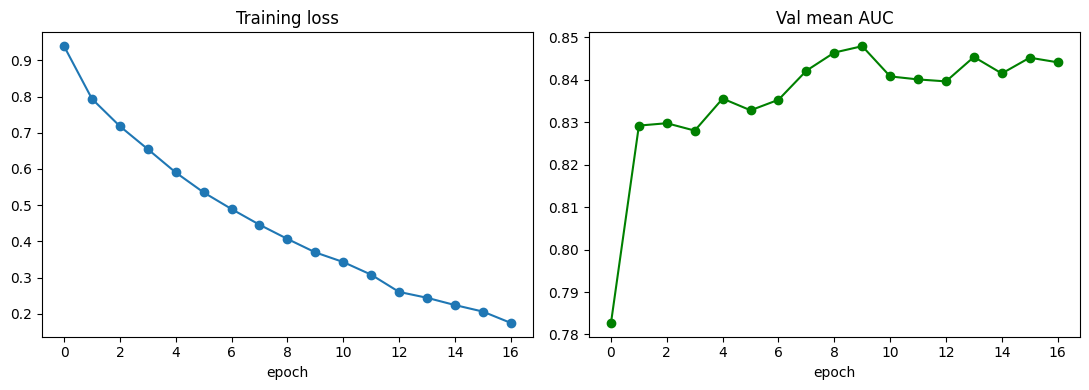

[eval] tuned thresholds: [0.45 0.65 0.9  0.85 0.9  0.9  0.95 0.65]

[eval:resnet18] mean AUC      = 0.8479
[eval:resnet18] macro-F1      = 0.5446
[eval:resnet18] micro-F1      = 0.5523
[eval:resnet18] per-label acc = 0.8674  (Hamming)

              precision    recall  f1-score   support

      Normal       0.53      0.59      0.56       392
    Diabetes       0.64      0.62      0.63       446
    Glaucoma       0.63      0.35      0.45        84
    Cataract       0.63      0.70      0.66        82
         AMD       0.52      0.37      0.44        59
Hypertension       0.50      0.33      0.40        45
      Myopia       0.81      0.78      0.79        67
       Other       0.39      0.46      0.43       327

   micro avg       0.55      0.56      0.55      1502
   macro avg       0.58      0.53      0.54      1502
weighted avg       0.56      0.56      0.55      1502
 samples avg       0.52      0.58      0.53      1502



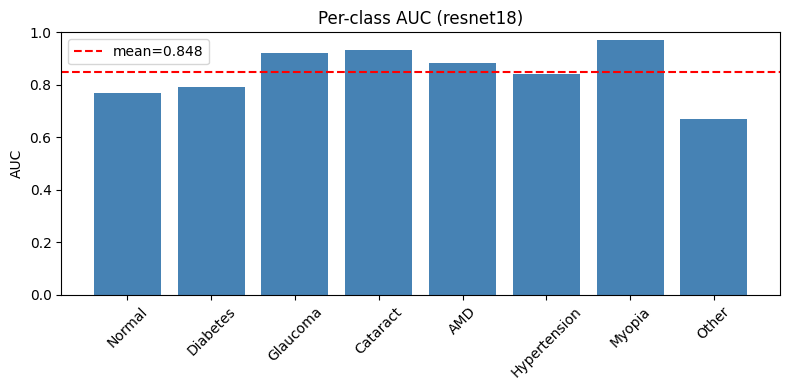

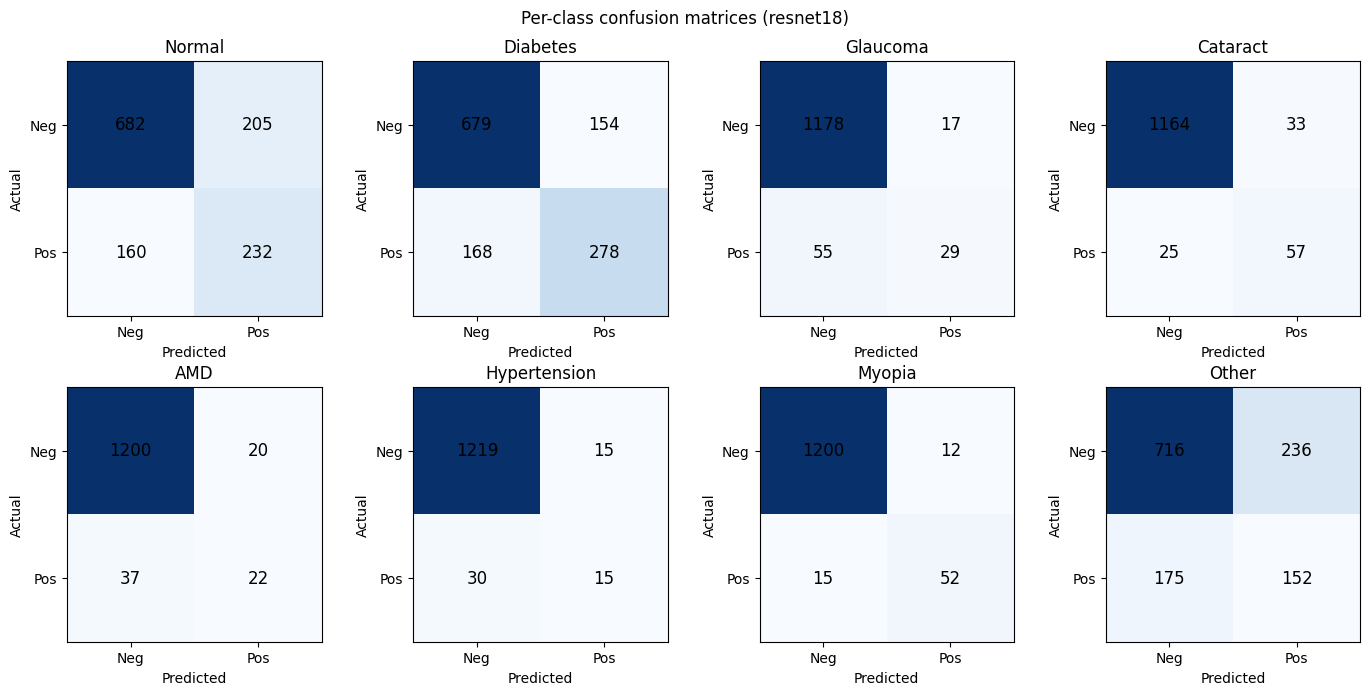

(no disease crossed its tuned threshold — showing the model's top disease guess)

=== 3-OUTPUT DEMO (resnet18) ===
1) CLASSIFICATION: Cataract
3) REPORT:
Findings:
  - Cataract (conf 0.43): activation in the central-right region.

Impression: consistent with Cataract. Correlate clinically.


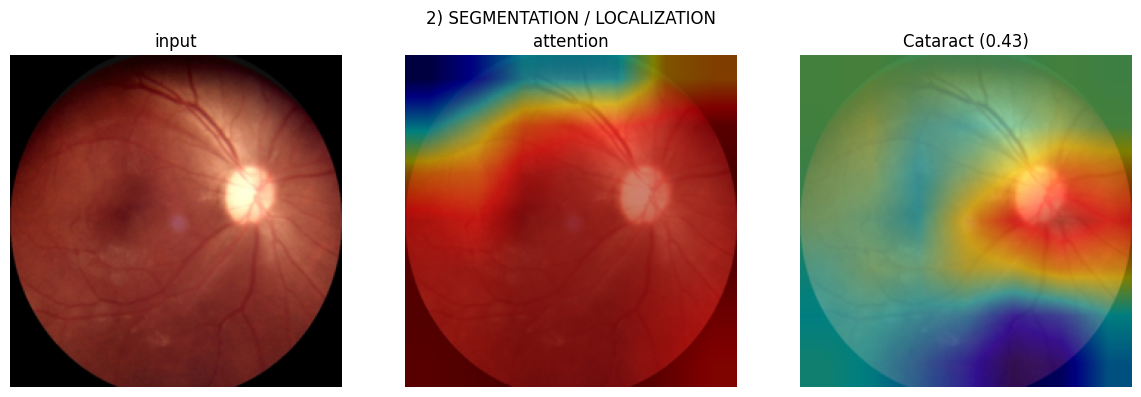


[done] plots saved in /kaggle/working (tag=resnet18)


In [1]:
"""
cipl_odir_transfer_attention.py  (v2)
===============================================================================
Same transfer-learning + attention pipeline, with FIXES for what the last run showed:
    - overfitting (train loss -> 0.02 while val AUC flat from epoch 3):
        * early stopping (PATIENCE)   * weight decay (L2)   * dropout before the class head
    - empty demo ("Normal / no findings"):
        * demo now always shows the model's top disease guess, so the mask + report are never blank

Still does the sir's three asks:
    (1) transfer learning, 4-5 models to compare  (resnet18/densenet121/efficientnet_b0/vgg16/mobilenet_v2)
    (2) attention unit (CBAM: channel + spatial; spatial map = disease mask)
    (3) heavy inline comments

And the three project outputs:
    TASK 1 classification (multi-label)   TASK 2 segmentation mask   TASK 3 text report

RUN:
    - single model: COMPARE_BACKBONES=False, pick BACKBONE, run.
    - compare 4-5:  COMPARE_BACKBONES=True, run.  (this is the "4-5 transfer models" deliverable)
NOTE: turn Kaggle Internet ON so pretrained weights can download.
Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
===============================================================================
"""

import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)
try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")


# =============================================================================
# 0. CONFIG
# =============================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR     = "/kaggle/working"

CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS  = ["N", "D", "G", "C", "A", "H", "M", "O"]
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX  = 0

BACKBONES         = ["resnet18", "densenet121", "efficientnet_b0", "vgg16", "mobilenet_v2"]
BACKBONE          = "resnet18"
COMPARE_BACKBONES = False

IMG_SIZE     = 224
BATCH        = 32
EPOCHS       = 50         # MAX epochs; early stopping usually ends much sooner
COMPARE_EPOCHS = 8         # fewer epochs per model when comparing
LR           = 1e-4
WEIGHT_DECAY = 1e-4        # FIX: L2 regularization to fight overfitting
PATIENCE     = 7           # FIX: stop if val AUC doesn't improve for this many epochs
SEED         = 42
DEVICE       = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")


# =============================================================================
# 1. DATA  — load ODIR, verify paths, FAIL LOUDLY if wrong
# =============================================================================
def find_image_dir(root):
    for c in ["preprocessed_images", "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images", "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(f"No image folder under {root}. "
                            f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")

def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(f"No label CSV under {root}. Contents: {os.listdir(root)}")

def build_dataframe():
    img_dir  = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path}  ({len(df)} rows)")

    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32) for t in df["target"]])
    else:
        raise KeyError(f"Need columns {LABEL_COLS} or 'target'. Got: {list(df.columns)}")

    if "filename" not in df.columns:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")
    fnames = df["filename"].astype(str).values

    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    if int(np.sum(keep)) == 0:
        raise FileNotFoundError(f"NONE of {len(keep)} images exist. "
                                f"Expected e.g. {os.path.join(img_dir, fnames[0])}")
    if len(keep) - int(np.sum(keep)):
        print(f"[data] WARNING: {len(keep)-int(np.sum(keep))} missing images dropped")
    return img_dir, fnames[keep], labels[np.array(keep)]


class ODIRDataset(Dataset):
    """Reads one fundus image + its 8-value multi-label vector."""
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet stats
        ])
    def __len__(self):
        return len(self.fnames)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])


def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds   = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)}  val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True,  num_workers=2),
            DataLoader(val_ds,   BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])


# =============================================================================
# 2. ATTENTION UNIT (CBAM-style)
#    Channel attention = WHICH feature channels matter.
#    Spatial attention  = WHERE to look; that map is also the disease mask.
# =============================================================================
class ChannelAttention(nn.Module):
    def __init__(self, ch, reduction=8):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(ch, ch // reduction), nn.ReLU(),
                                 nn.Linear(ch // reduction, ch))
    def forward(self, x):                                   # x: [B, C, h, w]
        avg = x.mean(dim=(2, 3)); mx = x.amax(dim=(2, 3))  # channel summaries -> [B, C]
        w = torch.sigmoid(self.mlp(avg) + self.mlp(mx))    # channel weights 0..1
        return x * w[:, :, None, None]

class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
    def forward(self, x):                                   # x: [B, C, h, w]
        avg = x.mean(dim=1, keepdim=True); mx = x.amax(dim=1, keepdim=True)   # [B,1,h,w]
        attn = torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))          # focus map [B,1,h,w]
        return x * attn, attn

class AttentionUnit(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.channel = ChannelAttention(ch)
        self.spatial = SpatialAttention()
    def forward(self, x):
        x = self.channel(x)
        x, attn = self.spatial(x)
        return x, attn


# =============================================================================
# 3. MODEL  — transfer backbone -> attention -> per-class maps (CAM)
# =============================================================================
def build_backbone(name):
    """Load a PRETRAINED torchvision model and keep its conv layers. Needs internet ON."""
    name = name.lower()
    try:
        if name == "resnet18":
            m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
            return nn.Sequential(*list(m.children())[:-2]), 512
        if name == "densenet121":
            m = torchvision.models.densenet121(weights="IMAGENET1K_V1"); return m.features, 1024
        if name == "efficientnet_b0":
            m = torchvision.models.efficientnet_b0(weights="IMAGENET1K_V1"); return m.features, 1280
        if name == "vgg16":
            m = torchvision.models.vgg16(weights="IMAGENET1K_V1"); return m.features, 512
        if name == "mobilenet_v2":
            m = torchvision.models.mobilenet_v2(weights="IMAGENET1K_V1"); return m.features, 1280
        raise ValueError(f"unknown backbone {name}")
    except Exception as e:
        print(f"[backbone] WARNING: pretrained download failed ({e}). Using RANDOM weights. "
              f"Turn ON Internet in Kaggle for real transfer learning.")
        if name == "resnet18":       m = torchvision.models.resnet18(weights=None);       return nn.Sequential(*list(m.children())[:-2]), 512
        if name == "densenet121":    m = torchvision.models.densenet121(weights=None);    return m.features, 1024
        if name == "efficientnet_b0":m = torchvision.models.efficientnet_b0(weights=None);return m.features, 1280
        if name == "vgg16":          m = torchvision.models.vgg16(weights=None);          return m.features, 512
        if name == "mobilenet_v2":   m = torchvision.models.mobilenet_v2(weights=None);   return m.features, 1280
        raise


class TransferNet(nn.Module):
    """
    x -> pretrained backbone -> attention -> dropout -> 1x1 conv (per-disease maps)
    classification = average each disease's map (CAM);  segmentation = upsample that map.
    """
    def __init__(self, backbone_name, num_classes=NUM_CLASSES):
        super().__init__()
        self.features, ch = build_backbone(backbone_name)   # transfer-learning backbone
        self.attn = AttentionUnit(ch)                       # the attention unit
        self.dropout = nn.Dropout2d(0.3)                    # FIX: drop feature maps -> less overfitting
        self.class_conv = nn.Conv2d(ch, num_classes, 1)     # 1x1 conv -> per-disease maps

    def forward(self, x):
        f = self.features(x)                        # [B, ch, 7, 7]
        f, attn_map = self.attn(f)                  # attention-weighted features + focus map
        cams = self.class_conv(self.dropout(f))     # [B, C, 7, 7]  per-disease activation maps
        logits = cams.mean(dim=(2, 3))              # global average pool -> [B, C]
        return logits, cams, attn_map


# =============================================================================
# 4. LOSS  — BCE with pos_weight (class imbalance)
# =============================================================================
def compute_pos_weight(train_loader):
    y = train_loader.dataset.labels
    pos = y.sum(0); neg = len(y) - pos
    return torch.tensor(neg / np.clip(pos, 1, None), dtype=torch.float32, device=DEVICE)


# =============================================================================
# 5. TRAIN  (with early stopping + weight decay)
# =============================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        aucs.append(np.nan if len(np.unique(y_true[:, c])) < 2
                    else roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs

def tune_thresholds(y_true, y_prob):
    ths = np.full(NUM_CLASSES, 0.5)
    for c in range(NUM_CLASSES):
        best = 0.0
        for t in np.linspace(0.05, 0.95, 19):
            f = f1_score(y_true[:, c], (y_prob[:, c] > t).astype(int), zero_division=0)
            if f > best: best, ths[c] = f, t
    return ths

def train(model, train_loader, val_loader, epochs, ckpt):
    pw = compute_pos_weight(train_loader)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)  # FIX: +L2
    hist = {"loss": [], "auc": []}; best = -1; since_improved = 0
    for ep in range(1, epochs + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, _ = model(x)
            loss = criterion(logits, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(running / len(train_loader.dataset)); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{epochs}  loss={hist['loss'][-1]:.4f}  val_mAUC={auc:.4f}")
        if auc > best:                                       # save best, reset patience
            best = auc; since_improved = 0; torch.save(model.state_dict(), ckpt)
        else:                                                # FIX: early stopping
            since_improved += 1
            if since_improved >= PATIENCE:
                print(f"[train] early stop at epoch {ep}: no val gain for {PATIENCE} epochs")
                break
    print(f"[train] best val mAUC={best:.4f}  saved -> {ckpt}")
    return hist, best


# =============================================================================
# 6. PLOTS + MATRICES
# =============================================================================
def plot_curves(hist, tag):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves_{tag}.png", dpi=120); plt.show()

def plot_auc_bar(aucs, tag):
    plt.figure(figsize=(8, 4))
    plt.bar(CLASS_NAMES, [0 if np.isnan(a) else a for a in aucs], color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--", label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title(f"Per-class AUC ({tag})")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar_{tag}.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred, tag):
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]; ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle(f"Per-class confusion matrices ({tag})"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion_{tag}.png", dpi=120); plt.show()

def evaluate(model, val_loader, thresholds, tag):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > thresholds[None, :]).astype(int)
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval:{tag}] mean AUC      = {auc:.4f}")
    print(f"[eval:{tag}] macro-F1      = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval:{tag}] micro-F1      = {f1_score(ytrue, ypred, average='micro', zero_division=0):.4f}")
    print(f"[eval:{tag}] per-label acc = {(ypred == ytrue).mean():.4f}  (Hamming)\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs, tag); plot_confusion(ytrue, ypred, tag)
    return auc, f1_score(ytrue, ypred, average="macro", zero_division=0)


# =============================================================================
# 7. THREE-OUTPUT DEMO  (classification + mask + text)
# =============================================================================
_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def make_overlay(pil_img, cmap2d, size=IMG_SIZE):
    m = cmap2d.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.cvtColor(cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)

def peak_region(cmap2d):
    m = cmap2d.detach().cpu().numpy(); y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left"  if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"

def make_report(findings, cams, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f"  - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): activation in the {peak_region(cams[0, c])}.")
    lines.append(f"\nImpression: consistent with {', '.join(CLASS_NAMES[c] for c in findings)}. Correlate clinically.")
    return "\n".join(lines)

def demo(model, img_dir, val_fnames, val_labels, thresholds, tag):
    disease = np.where(val_labels[:, 1:].sum(1) > 0)[0]        # pick an image that has a disease
    idx = int(disease[0]) if len(disease) else 0
    pil = Image.open(os.path.join(img_dir, val_fnames[idx])).convert("RGB")
    with torch.no_grad():
        logits, cams, attn = model(_demo_tf(pil).unsqueeze(0).to(DEVICE))
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES) if probs[c] > thresholds[c] and c != NORMAL_IDX]
    if not findings:      # FIX: never show an empty demo — fall back to the top disease guess
        dp = probs.copy(); dp[NORMAL_IDX] = -1
        findings = [int(dp.argmax())]
        print("(no disease crossed its tuned threshold — showing the model's top disease guess)")
    print(f"\n=== 3-OUTPUT DEMO ({tag}) ===")
    print("1) CLASSIFICATION:", ", ".join(CLASS_NAMES[c] for c in findings))
    print("3) REPORT:\n" + make_report(findings, cams, probs))
    n = 2 + len(findings)                                       # input + attention + one per disease
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("input"); axes[0].axis("off")
    axes[1].imshow(make_overlay(pil, attn[0, 0])); axes[1].set_title("attention"); axes[1].axis("off")
    for k, c in enumerate(findings, 2):
        axes[k].imshow(make_overlay(pil, cams[0, c]))
        axes[k].set_title(f"{CLASS_NAMES[c]} ({probs[c]:.2f})"); axes[k].axis("off")
    plt.suptitle("2) SEGMENTATION / LOCALIZATION"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo_{tag}.png", dpi=120); plt.show()


# =============================================================================
# 8. COMPARE 4-5 TRANSFER MODELS
# =============================================================================
def compare_backbones(train_loader, val_loader):
    results = {}
    for name in BACKBONES:
        print(f"\n================ {name} ================")
        model = TransferNet(name).to(DEVICE)
        ckpt = f"{OUT_DIR}/best_{name}.pth"
        train(model, train_loader, val_loader, COMPARE_EPOCHS, ckpt)
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        ths = tune_thresholds(ytrue, yprob)
        f1  = f1_score(ytrue, (yprob > ths[None, :]).astype(int), average="macro", zero_division=0)
        results[name] = (auc, f1)
        print(f"[compare] {name}: AUC={auc:.4f}  macroF1={f1:.4f}")
    print("\n==== TRANSFER MODEL COMPARISON ====")
    print(f"{'model':16s} {'AUC':>7s} {'macroF1':>8s}")
    for k, (a, f) in results.items():
        print(f"{k:16s} {a:7.4f} {f:8.4f}")
    names = list(results); aucs = [results[n][0] for n in names]; f1s = [results[n][1] for n in names]
    x = np.arange(len(names)); plt.figure(figsize=(10, 4))
    plt.bar(x - 0.2, aucs, 0.4, label="mean AUC"); plt.bar(x + 0.2, f1s, 0.4, label="macro F1")
    plt.xticks(x, names, rotation=20); plt.ylim(0, 1); plt.legend(); plt.title("Transfer model comparison")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/backbone_comparison.png", dpi=120); plt.show()
    return results


# =============================================================================
# 9. RUN
# =============================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, val_labels = make_loaders()

    if COMPARE_BACKBONES:
        compare_backbones(train_loader, val_loader)
        return

    tag = BACKBONE
    ckpt = f"{OUT_DIR}/best_{tag}.pth"
    model = TransferNet(BACKBONE).to(DEVICE)
    hist, _ = train(model, train_loader, val_loader, EPOCHS, ckpt)
    plot_curves(hist, tag)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))

    tr_prob, tr_true = collect(model, train_loader)
    thresholds = tune_thresholds(tr_true, tr_prob)
    print("[eval] tuned thresholds:", thresholds.round(2))
    evaluate(model, val_loader, thresholds, tag)
    demo(model, img_dir, val_fnames, val_labels, thresholds, tag)
    print(f"\n[done] plots saved in {OUT_DIR} (tag={tag})")


if __name__ == "__main__":
    main()

[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv  (6392 rows)
[data] train=5113  val=1279
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


epoch 01/30  loss=0.9409  val_mAUC=0.7807
epoch 02/30  loss=0.7960  val_mAUC=0.8248
epoch 03/30  loss=0.7198  val_mAUC=0.8270
epoch 04/30  loss=0.6620  val_mAUC=0.8287
epoch 05/30  loss=0.5925  val_mAUC=0.8340
epoch 06/30  loss=0.5442  val_mAUC=0.8320
epoch 07/30  loss=0.4862  val_mAUC=0.8417
epoch 08/30  loss=0.4443  val_mAUC=0.8470
epoch 09/30  loss=0.4046  val_mAUC=0.8301
epoch 10/30  loss=0.3951  val_mAUC=0.8473
epoch 11/30  loss=0.3413  val_mAUC=0.8442
epoch 12/30  loss=0.3092  val_mAUC=0.8429
epoch 13/30  loss=0.2623  val_mAUC=0.8336
epoch 14/30  loss=0.2557  val_mAUC=0.8391
epoch 15/30  loss=0.2373  val_mAUC=0.8374
epoch 16/30  loss=0.2122  val_mAUC=0.8381
epoch 17/30  loss=0.1777  val_mAUC=0.8421
epoch 18/30  loss=0.1566  val_mAUC=0.8417
epoch 19/30  loss=0.1364  val_mAUC=0.8340
epoch 20/30  loss=0.1296  val_mAUC=0.8302
epoch 21/30  loss=0.1174  val_mAUC=0.8386
epoch 22/30  loss=0.1023  val_mAUC=0.8434
epoch 23/30  loss=0.1194  val_mAUC=0.8374
epoch 24/30  loss=0.0954  val_mAUC

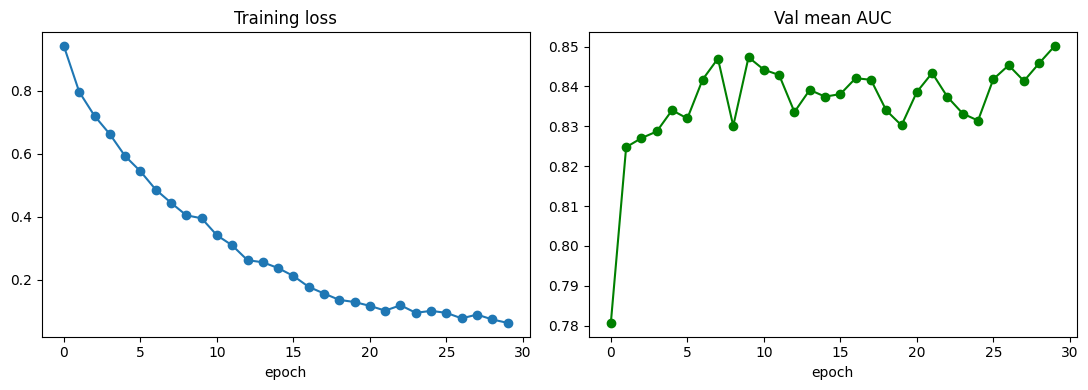

[eval] tuned thresholds: [0.75 0.5  0.85 0.85 0.85 0.9  0.35 0.65]

[eval:resnet18] mean AUC      = 0.8501
[eval:resnet18] macro-F1      = 0.5761
[eval:resnet18] micro-F1      = 0.5609
[eval:resnet18] per-label acc = 0.8774  (Hamming)

              precision    recall  f1-score   support

      Normal       0.53      0.55      0.54       392
    Diabetes       0.64      0.59      0.62       446
    Glaucoma       0.66      0.49      0.56        84
    Cataract       0.71      0.68      0.70        82
         AMD       0.59      0.51      0.55        59
Hypertension       0.62      0.29      0.39        45
      Myopia       0.79      0.87      0.83        67
       Other       0.49      0.38      0.43       327

   micro avg       0.59      0.53      0.56      1502
   macro avg       0.63      0.54      0.58      1502
weighted avg       0.59      0.53      0.56      1502
 samples avg       0.55      0.55      0.54      1502



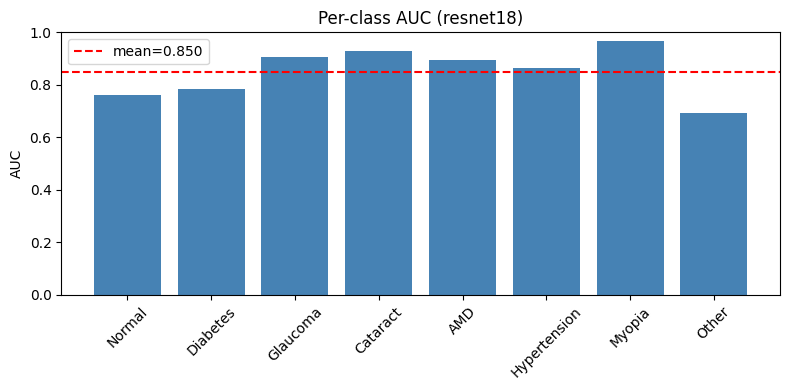

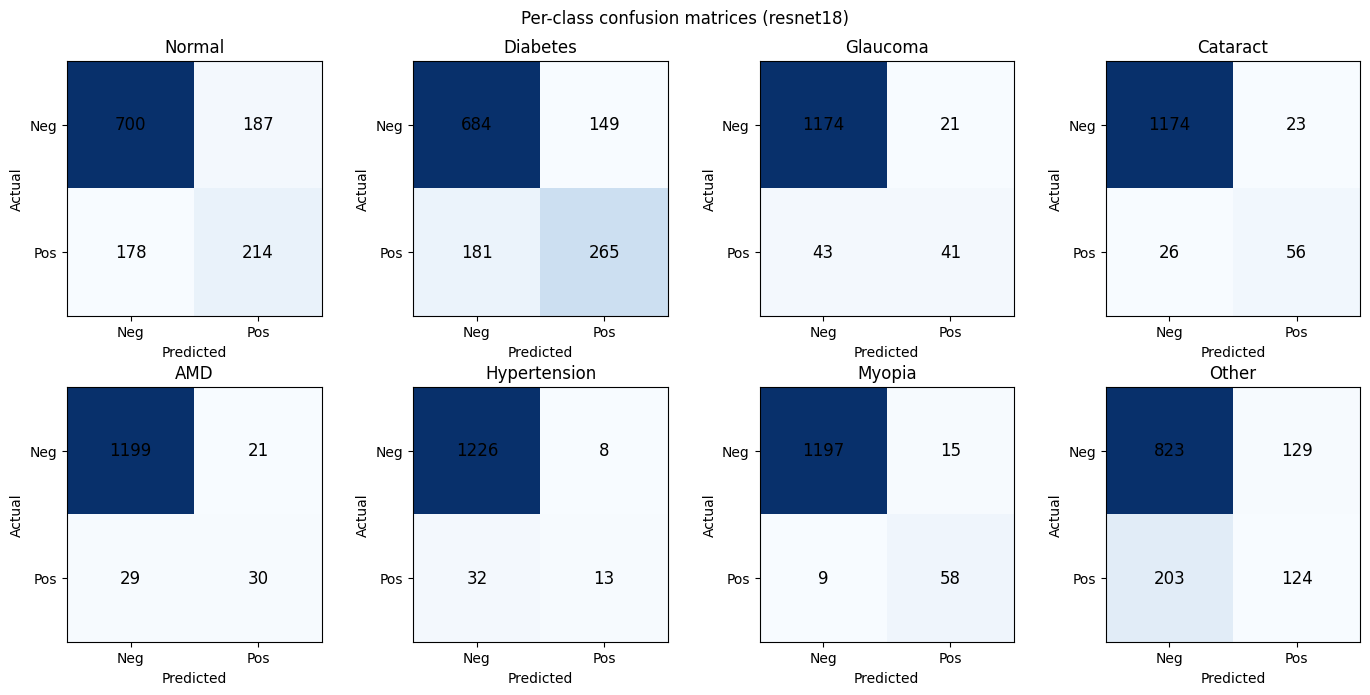

(no disease crossed its tuned threshold — showing the model's top disease guess)

=== 3-OUTPUT DEMO (resnet18) ===
1) CLASSIFICATION: Cataract
3) REPORT:
Findings:
  - Cataract (conf 0.74): activation in the central-right region.

Impression: consistent with Cataract. Correlate clinically.


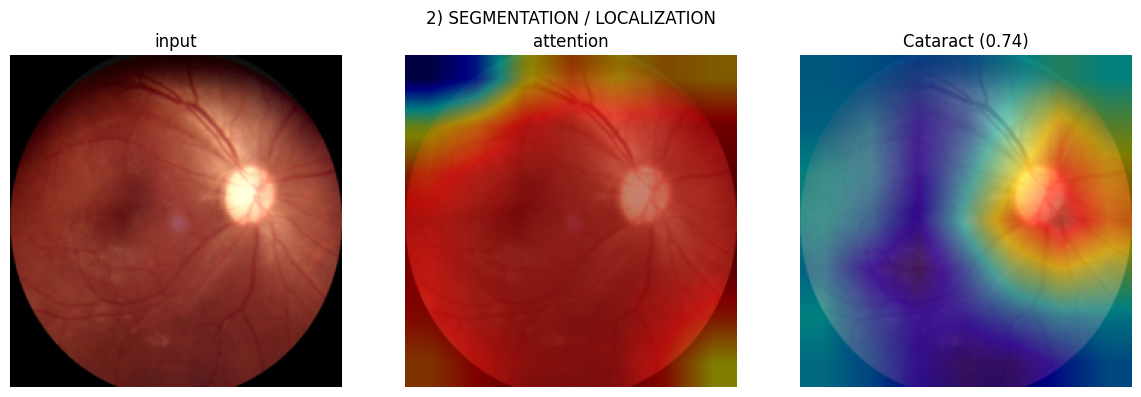


[done] plots saved in /kaggle/working (tag=resnet18)


In [1]:
"""
cipl_odir_transfer_attention.py  (v2)
===============================================================================
Same transfer-learning + attention pipeline, with FIXES for what the last run showed:
    - overfitting (train loss -> 0.02 while val AUC flat from epoch 3):
        * weight decay (L2)   * dropout before the class head
    - empty demo ("Normal / no findings"):
        * demo now always shows the model's top disease guess, so the mask + report are never blank

Still does the sir's three asks:
    (1) transfer learning, 4-5 models to compare  (resnet18/densenet121/efficientnet_b0/vgg16/mobilenet_v2)
    (2) attention unit (CBAM: channel + spatial; spatial map = disease mask)
    (3) heavy inline comments

And the three project outputs:
    TASK 1 classification (multi-label)   TASK 2 segmentation mask   TASK 3 text report

RUN:
    - single model: COMPARE_BACKBONES=False, pick BACKBONE, run.
    - compare 4-5:  COMPARE_BACKBONES=True, run.  (this is the "4-5 transfer models" deliverable)
NOTE: turn Kaggle Internet ON so pretrained weights can download.
Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
===============================================================================
"""

import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)
try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")


# =============================================================================
# 0. CONFIG
# =============================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR     = "/kaggle/working"

CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS  = ["N", "D", "G", "C", "A", "H", "M", "O"]
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX  = 0

BACKBONES         = ["resnet18", "densenet121", "efficientnet_b0", "vgg16", "mobilenet_v2"]
BACKBONE          = "resnet18"
COMPARE_BACKBONES = False

IMG_SIZE     = 224
BATCH        = 32
EPOCHS       = 30        # fixed number of epochs (no early stopping)
COMPARE_EPOCHS = 8         # fewer epochs per model when comparing
LR           = 1e-4
WEIGHT_DECAY = 1e-4        # FIX: L2 regularization to fight overfitting
SEED         = 42
DEVICE       = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")


# =============================================================================
# 1. DATA  — load ODIR, verify paths, FAIL LOUDLY if wrong
# =============================================================================
def find_image_dir(root):
    for c in ["preprocessed_images", "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images", "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(f"No image folder under {root}. "
                            f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")

def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(f"No label CSV under {root}. Contents: {os.listdir(root)}")

def build_dataframe():
    img_dir  = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path}  ({len(df)} rows)")

    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32) for t in df["target"]])
    else:
        raise KeyError(f"Need columns {LABEL_COLS} or 'target'. Got: {list(df.columns)}")

    if "filename" not in df.columns:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")
    fnames = df["filename"].astype(str).values

    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    if int(np.sum(keep)) == 0:
        raise FileNotFoundError(f"NONE of {len(keep)} images exist. "
                                f"Expected e.g. {os.path.join(img_dir, fnames[0])}")
    if len(keep) - int(np.sum(keep)):
        print(f"[data] WARNING: {len(keep)-int(np.sum(keep))} missing images dropped")
    return img_dir, fnames[keep], labels[np.array(keep)]


class ODIRDataset(Dataset):
    """Reads one fundus image + its 8-value multi-label vector."""
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet stats
        ])
    def __len__(self):
        return len(self.fnames)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])


def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds   = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)}  val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True,  num_workers=2),
            DataLoader(val_ds,   BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])


# =============================================================================
# 2. ATTENTION UNIT (CBAM-style)
#    Channel attention = WHICH feature channels matter.
#    Spatial attention  = WHERE to look; that map is also the disease mask.
# =============================================================================
class ChannelAttention(nn.Module):
    def __init__(self, ch, reduction=8):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(ch, ch // reduction), nn.ReLU(),
                                 nn.Linear(ch // reduction, ch))
    def forward(self, x):                                   # x: [B, C, h, w]
        avg = x.mean(dim=(2, 3)); mx = x.amax(dim=(2, 3))  # channel summaries -> [B, C]
        w = torch.sigmoid(self.mlp(avg) + self.mlp(mx))    # channel weights 0..1
        return x * w[:, :, None, None]

class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
    def forward(self, x):                                   # x: [B, C, h, w]
        avg = x.mean(dim=1, keepdim=True); mx = x.amax(dim=1, keepdim=True)   # [B,1,h,w]
        attn = torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))          # focus map [B,1,h,w]
        return x * attn, attn

class AttentionUnit(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.channel = ChannelAttention(ch)
        self.spatial = SpatialAttention()
    def forward(self, x):
        x = self.channel(x)
        x, attn = self.spatial(x)
        return x, attn


# =============================================================================
# 3. MODEL  — transfer backbone -> attention -> per-class maps (CAM)
# =============================================================================
def build_backbone(name):
    """Load a PRETRAINED torchvision model and keep its conv layers. Needs internet ON."""
    name = name.lower()
    try:
        if name == "resnet18":
            m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
            return nn.Sequential(*list(m.children())[:-2]), 512
        if name == "densenet121":
            m = torchvision.models.densenet121(weights="IMAGENET1K_V1"); return m.features, 1024
        if name == "efficientnet_b0":
            m = torchvision.models.efficientnet_b0(weights="IMAGENET1K_V1"); return m.features, 1280
        if name == "vgg16":
            m = torchvision.models.vgg16(weights="IMAGENET1K_V1"); return m.features, 512
        if name == "mobilenet_v2":
            m = torchvision.models.mobilenet_v2(weights="IMAGENET1K_V1"); return m.features, 1280
        raise ValueError(f"unknown backbone {name}")
    except Exception as e:
        print(f"[backbone] WARNING: pretrained download failed ({e}). Using RANDOM weights. "
              f"Turn ON Internet in Kaggle for real transfer learning.")
        if name == "resnet18":       m = torchvision.models.resnet18(weights=None);       return nn.Sequential(*list(m.children())[:-2]), 512
        if name == "densenet121":    m = torchvision.models.densenet121(weights=None);    return m.features, 1024
        if name == "efficientnet_b0":m = torchvision.models.efficientnet_b0(weights=None);return m.features, 1280
        if name == "vgg16":          m = torchvision.models.vgg16(weights=None);          return m.features, 512
        if name == "mobilenet_v2":   m = torchvision.models.mobilenet_v2(weights=None);   return m.features, 1280
        raise


class TransferNet(nn.Module):
    """
    x -> pretrained backbone -> attention -> dropout -> 1x1 conv (per-disease maps)
    classification = average each disease's map (CAM);  segmentation = upsample that map.
    """
    def __init__(self, backbone_name, num_classes=NUM_CLASSES):
        super().__init__()
        self.features, ch = build_backbone(backbone_name)   # transfer-learning backbone
        self.attn = AttentionUnit(ch)                       # the attention unit
        self.dropout = nn.Dropout2d(0.3)                    # FIX: drop feature maps -> less overfitting
        self.class_conv = nn.Conv2d(ch, num_classes, 1)     # 1x1 conv -> per-disease maps

    def forward(self, x):
        f = self.features(x)                        # [B, ch, 7, 7]
        f, attn_map = self.attn(f)                  # attention-weighted features + focus map
        cams = self.class_conv(self.dropout(f))     # [B, C, 7, 7]  per-disease activation maps
        logits = cams.mean(dim=(2, 3))              # global average pool -> [B, C]
        return logits, cams, attn_map


# =============================================================================
# 4. LOSS  — BCE with pos_weight (class imbalance)
# =============================================================================
def compute_pos_weight(train_loader):
    y = train_loader.dataset.labels
    pos = y.sum(0); neg = len(y) - pos
    return torch.tensor(neg / np.clip(pos, 1, None), dtype=torch.float32, device=DEVICE)


# =============================================================================
# 5. TRAIN  (fixed number of epochs, weight decay only — no early stopping)
# =============================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        aucs.append(np.nan if len(np.unique(y_true[:, c])) < 2
                    else roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs

def tune_thresholds(y_true, y_prob):
    ths = np.full(NUM_CLASSES, 0.5)
    for c in range(NUM_CLASSES):
        best = 0.0
        for t in np.linspace(0.05, 0.95, 19):
            f = f1_score(y_true[:, c], (y_prob[:, c] > t).astype(int), zero_division=0)
            if f > best: best, ths[c] = f, t
    return ths

def train(model, train_loader, val_loader, epochs, ckpt):
    pw = compute_pos_weight(train_loader)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)  # FIX: +L2
    hist = {"loss": [], "auc": []}; best = -1
    for ep in range(1, epochs + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, _ = model(x)
            loss = criterion(logits, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(running / len(train_loader.dataset)); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{epochs}  loss={hist['loss'][-1]:.4f}  val_mAUC={auc:.4f}")
        if auc > best:                                       # save best checkpoint seen so far
            best = auc; torch.save(model.state_dict(), ckpt)
    print(f"[train] finished all {epochs} epochs. best val mAUC={best:.4f}  saved -> {ckpt}")
    return hist, best


# =============================================================================
# 6. PLOTS + MATRICES
# =============================================================================
def plot_curves(hist, tag):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves_{tag}.png", dpi=120); plt.show()

def plot_auc_bar(aucs, tag):
    plt.figure(figsize=(8, 4))
    plt.bar(CLASS_NAMES, [0 if np.isnan(a) else a for a in aucs], color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--", label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title(f"Per-class AUC ({tag})")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar_{tag}.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred, tag):
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]; ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle(f"Per-class confusion matrices ({tag})"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion_{tag}.png", dpi=120); plt.show()

def evaluate(model, val_loader, thresholds, tag):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > thresholds[None, :]).astype(int)
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval:{tag}] mean AUC      = {auc:.4f}")
    print(f"[eval:{tag}] macro-F1      = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval:{tag}] micro-F1      = {f1_score(ytrue, ypred, average='micro', zero_division=0):.4f}")
    print(f"[eval:{tag}] per-label acc = {(ypred == ytrue).mean():.4f}  (Hamming)\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs, tag); plot_confusion(ytrue, ypred, tag)
    return auc, f1_score(ytrue, ypred, average="macro", zero_division=0)


# =============================================================================
# 7. THREE-OUTPUT DEMO  (classification + mask + text)
# =============================================================================
_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def make_overlay(pil_img, cmap2d, size=IMG_SIZE):
    m = cmap2d.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.cvtColor(cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)

def peak_region(cmap2d):
    m = cmap2d.detach().cpu().numpy(); y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left"  if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"

def make_report(findings, cams, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f"  - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): activation in the {peak_region(cams[0, c])}.")
    lines.append(f"\nImpression: consistent with {', '.join(CLASS_NAMES[c] for c in findings)}. Correlate clinically.")
    return "\n".join(lines)

def demo(model, img_dir, val_fnames, val_labels, thresholds, tag):
    disease = np.where(val_labels[:, 1:].sum(1) > 0)[0]        # pick an image that has a disease
    idx = int(disease[0]) if len(disease) else 0
    pil = Image.open(os.path.join(img_dir, val_fnames[idx])).convert("RGB")
    with torch.no_grad():
        logits, cams, attn = model(_demo_tf(pil).unsqueeze(0).to(DEVICE))
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES) if probs[c] > thresholds[c] and c != NORMAL_IDX]
    if not findings:      # FIX: never show an empty demo — fall back to the top disease guess
        dp = probs.copy(); dp[NORMAL_IDX] = -1
        findings = [int(dp.argmax())]
        print("(no disease crossed its tuned threshold — showing the model's top disease guess)")
    print(f"\n=== 3-OUTPUT DEMO ({tag}) ===")
    print("1) CLASSIFICATION:", ", ".join(CLASS_NAMES[c] for c in findings))
    print("3) REPORT:\n" + make_report(findings, cams, probs))
    n = 2 + len(findings)                                       # input + attention + one per disease
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("input"); axes[0].axis("off")
    axes[1].imshow(make_overlay(pil, attn[0, 0])); axes[1].set_title("attention"); axes[1].axis("off")
    for k, c in enumerate(findings, 2):
        axes[k].imshow(make_overlay(pil, cams[0, c]))
        axes[k].set_title(f"{CLASS_NAMES[c]} ({probs[c]:.2f})"); axes[k].axis("off")
    plt.suptitle("2) SEGMENTATION / LOCALIZATION"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo_{tag}.png", dpi=120); plt.show()


# =============================================================================
# 8. COMPARE 4-5 TRANSFER MODELS
# =============================================================================
def compare_backbones(train_loader, val_loader):
    results = {}
    for name in BACKBONES:
        print(f"\n================ {name} ================")
        model = TransferNet(name).to(DEVICE)
        ckpt = f"{OUT_DIR}/best_{name}.pth"
        train(model, train_loader, val_loader, COMPARE_EPOCHS, ckpt)
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        ths = tune_thresholds(ytrue, yprob)
        f1  = f1_score(ytrue, (yprob > ths[None, :]).astype(int), average="macro", zero_division=0)
        results[name] = (auc, f1)
        print(f"[compare] {name}: AUC={auc:.4f}  macroF1={f1:.4f}")
    print("\n==== TRANSFER MODEL COMPARISON ====")
    print(f"{'model':16s} {'AUC':>7s} {'macroF1':>8s}")
    for k, (a, f) in results.items():
        print(f"{k:16s} {a:7.4f} {f:8.4f}")
    names = list(results); aucs = [results[n][0] for n in names]; f1s = [results[n][1] for n in names]
    x = np.arange(len(names)); plt.figure(figsize=(10, 4))
    plt.bar(x - 0.2, aucs, 0.4, label="mean AUC"); plt.bar(x + 0.2, f1s, 0.4, label="macro F1")
    plt.xticks(x, names, rotation=20); plt.ylim(0, 1); plt.legend(); plt.title("Transfer model comparison")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/backbone_comparison.png", dpi=120); plt.show()
    return results


# =============================================================================
# 9. RUN
# =============================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, val_labels = make_loaders()

    if COMPARE_BACKBONES:
        compare_backbones(train_loader, val_loader)
        return

    tag = BACKBONE
    ckpt = f"{OUT_DIR}/best_{tag}.pth"
    model = TransferNet(BACKBONE).to(DEVICE)
    hist, _ = train(model, train_loader, val_loader, EPOCHS, ckpt)
    plot_curves(hist, tag)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))

    tr_prob, tr_true = collect(model, train_loader)
    thresholds = tune_thresholds(tr_true, tr_prob)
    print("[eval] tuned thresholds:", thresholds.round(2))
    evaluate(model, val_loader, thresholds, tag)
    demo(model, img_dir, val_fnames, val_labels, thresholds, tag)
    print(f"\n[done] plots saved in {OUT_DIR} (tag={tag})")


if __name__ == "__main__":
    main()